# 🦅 APT + FFN-Adapter (Layer 9–11 | Uniform PPF (α=0.70)) — CUB-200 (Train/Val 5-Fold & Test)

## 📌 Bối cảnh & Động lực Nghiên cứu
* **Vấn đề từ thực nghiệm trước**:
  * Khi đặt Adapter ở cả 12 tầng (Full-depth), mô hình đạt độ chính xác rất cao ở 5T và 10T ($>88.7\%$).
  * Tuy nhiên ở 20T và 40T, việc merge trọng số Adapter ở các tầng nông quá nhiều lần gây hiện tượng **Weight Drift / Over-smoothing** (làm mờ các đặc trưng thị giác thô vốn đã rất tốt từ pretrained ImageNet-21k).
* **Giải pháp: Chuyên biệt hóa Adapter tại Deep Layers (Layer 9–11)**:
  * **Tầng nông (Layer 0–8)**: **Đóng băng 100% FFN**, hoàn toàn không cấy Adapter. Điều này bảo vệ tối đa các đặc trưng thị giác tổng quát (cạnh, góc, màu sắc cơ bản) không bị trôi dạt tham số qua nhiều task.
  * **Tầng sâu (Layer 9–11, 3 tầng)**: Cấy **Parallel Bottleneck Adapter** ($r=16$) để biến đổi ngữ nghĩa phi tuyến chuyên biệt cho phân loại các loài chim.
  * **Tiết kiệm tham số**: Chỉ tiêu tốn 3 × 0.025M $\approx$ **0.075M tham số** (giảm đáng kể so với 0.30M của Full-depth).
* **Cơ chế PPF (Uniform PPF (α=0.70))**:
  * Hợp nhất trọng số Prompt và 3 tầng Adapter sau mỗi task theo cơ chế **Uniform PPF (α=0.70)**.
* **Giao thức dữ liệu (`check-dataset.ipynb`)**: Chạy giai đoạn kiểm định `phase="val"` (80% Train / 20% Val) trên toàn bộ 4 kịch bản `task_splits = [5, 10, 20, 40]` qua 3 seeds `[0, 1, 2]` để tìm cấu hình tối ưu trước khi chạy test.


## 1. Cài đặt Môi trường & Thư viện
* Kích hoạt `line_buffering=True` để Kaggle Console / Viewer hiển thị logs thời gian thực.
* Tự động cài đặt thư viện `timm` nếu môi trường chưa có.
* Cấu hình tối ưu hóa phần cứng PyTorch trên GPU T4.


In [1]:
import os, sys, json, time, math, random, subprocess, warnings
warnings.filterwarnings("ignore")

# Đảm bảo hiển thị log tức thì trên Kaggle Console / Viewer
if hasattr(sys.stdout, "reconfigure"):
    sys.stdout.reconfigure(line_buffering=True)

try:
    import timm
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "timm"], check=True)
    import timm

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision.datasets import ImageFolder
from torchvision import transforms as T
from PIL import Image

print(f"torch {torch.__version__} | timm {timm.__version__}", flush=True)
assert torch.cuda.is_available(), "⚠️ Chưa bật GPU: Hãy vào Settings → Accelerator → GPU T4 x2"
DEVICE = "cuda"
print(f"✅ GPU đang hoạt động: {torch.cuda.get_device_name(0)}", flush=True)
torch.backends.cudnn.benchmark = True
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True


torch 2.11.0+cu128 | timm 1.0.29
✅ GPU đang hoạt động: Tesla T4


## 2. Cấu hình Thực nghiệm (`CFG`)
* `adapter_layers`: `[9, 10, 11]` (Layer 9–11).
* `ppf_mode`: `"uniform"` (Uniform PPF (α=0.70)).
* `adapter_bottleneck`: 16 (chiều ẩn bottleneck của FFN Adapter).
* `adapter_scale`: 0.1 (hệ số residual scale của Adapter).
* `adapter_lr`: 0.005 (learning rate cho Adapter).
* `phases`: `["val"]` (chỉ chạy kiểm định trên tập val 80/20 để tối ưu thời gian tìm best model).
* `task_splits`: `[5, 10, 20, 40]` (khảo sát toàn diện 4 kịch bản task: 5T, 10T, 20T, 40T).


In [2]:
CFG = dict(
    seeds=[0, 1, 2],           # 3 seed tương ứng 3 fold val độc lập (0% overlap) và 3 trật tự task
    phases=["val"],            # Chỉ chạy 'val' để tối ưu thời gian tìm best
    n_classes=200,
    n_tasks=10,                # n_tasks mặc định, sẽ được cập nhật tự động theo task_splits
    task_splits=[5, 10, 20, 40], # CUB-200: 5T (40 lớp), 10T (20 lớp), 20T (10 lớp), 40T (5 lớp)
    max_tasks=None,            # None: chạy đủ tất cả các task trong split; đặt số nguyên (vd: 2) để test nhanh
    epochs=20,                 # APT paper: 18-20 epoch/task cho CUB-200
    batch_size=128,
    prompt_lr=0.02,            # lr của APT prompt
    adapter_lr=0.005,          # lr của FFN Adapter
    adapter_layers=[9, 10, 11], # Layer 9–11
    adapter_bottleneck=16,     # Bottleneck rank r=16
    adapter_scale=0.1,          # Residual scale s=0.1
    head_lr={"linear": 0.02, "kac": 1e-3, "hybrid_cos": 0.02, "hybrid_kac": 1e-3},
    ema_coeff=0.7,             # Hệ số PPF gốc
    ppf_mode="uniform",     # "uniform"
    alpha_range=(0.85, 0.55),  # (alpha_shallow, alpha_deep), mean = 0.70
    clf_types=["hybrid"],      # APT + Adapter + Hybrid Classifier
    tau=2.0,                   # Temperature scaling cho Cosine Head
    alpha=1.5,                 # Trọng số kết hợp KAC Head
    kac_num_grids=4,           # KAC paper: 4 knot grids
    kac_grid_range=(-2.0, 2.0),
    use_amp=True,              # Tăng tốc độ với FP16 backbone
    num_workers=2,             # Ổn định nhất cho môi trường Kaggle 2 vCPUs
    max_train_batches=None,    # Debug: giới hạn batch mỗi epoch
    cub_dir="/kaggle/input/datasets/cyizhuo/cub-200-2011-by-classes-folder",
    out_dir="/kaggle/working/outputs_adapter_deep9_11_uniform",
    timm_name="vit_base_patch16_224.augreg_in21k_ft_in1k",
)

DEBUG = False   # True: chạy siêu nhanh 2 task x 1 epoch để test code
if DEBUG:
    CFG.update(seeds=[0], phases=["val"], max_tasks=2, epochs=1, max_train_batches=3)

os.makedirs(CFG["out_dir"], exist_ok=True)
print(json.dumps(CFG, indent=2), flush=True)


{
  "seeds": [
    0,
    1,
    2
  ],
  "phases": [
    "val"
  ],
  "n_classes": 200,
  "n_tasks": 10,
  "task_splits": [
    5,
    10,
    20,
    40
  ],
  "max_tasks": null,
  "epochs": 20,
  "batch_size": 128,
  "prompt_lr": 0.02,
  "adapter_lr": 0.005,
  "adapter_layers": [
    9,
    10,
    11
  ],
  "adapter_bottleneck": 16,
  "adapter_scale": 0.1,
  "head_lr": {
    "linear": 0.02,
    "kac": 0.001,
    "hybrid_cos": 0.02,
    "hybrid_kac": 0.001
  },
  "ema_coeff": 0.7,
  "ppf_mode": "uniform",
  "alpha_range": [
    0.85,
    0.55
  ],
  "clf_types": [
    "hybrid"
  ],
  "tau": 2.0,
  "alpha": 1.5,
  "kac_num_grids": 4,
  "kac_grid_range": [
    -2.0,
    2.0
  ],
  "use_amp": true,
  "num_workers": 2,
  "max_train_batches": null,
  "cub_dir": "/kaggle/input/datasets/cyizhuo/cub-200-2011-by-classes-folder",
  "out_dir": "/kaggle/working/outputs_adapter_deep9_11_uniform",
  "timm_name": "vit_base_patch16_224.augreg_in21k_ft_in1k"
}


## 3. Dữ liệu CUB-200 & Giao thức Chia Train / Val / Test
1. **`setup_cub200_seed`**: 
   - Đảo thứ tự lớp vào các task theo `seed`.
   - Chia Stratified Disjoint 5-Fold bên trong từng lớp: Fold `seed` làm Val (20%), 4 Fold còn lại làm Train (80%).
2. **`get_task_subsets`**:
   - Ở `phase="val"`: Trích xuất 80% Train của task hiện tại, và 20% Val của tất cả các lớp đã học tới task $t$.
   - Ở `phase="test"`: Trích xuất 100% Train gốc của task hiện tại, và Test chính thức của tất cả các lớp đã học tới task $t$.
3. **`RemapTransformDataset`**: Bọc `Subset` để ánh xạ nhãn gốc (0..199) sang nhãn lớp tuần tự $[t \cdot \text{per}, (t+1) \cdot \text{per})$ phù hợp với cấu trúc phân loại của Continual Learning, đồng thời áp dụng `TRAIN_TF` hoặc `TEST_TF`.


In [3]:
# 1. Tự động nhận diện đường dẫn CUB-200-2011 trên Kaggle
CUB_CANDIDATES = [
    CFG["cub_dir"],
    "/kaggle/input/datasets/cyizhuo/cub-200-2011-by-classes-folder",
    "/kaggle/input/cub-200-2011-by-classes-folder",
]
CUB_ROOT = next((p for p in CUB_CANDIDATES if os.path.isdir(os.path.join(p, "train")) and os.path.isdir(os.path.join(p, "test"))), CUB_CANDIDATES[0])

# 2. Hàm chuẩn: vừa đảo thứ tự Task theo seed, vừa lấy Fold[seed] làm Val (0% overlap)
def setup_cub200_seed(train_dataset, seed, num_classes=200, task_sizes=None, n_splits=5, base_seed=1993):
    assert 0 <= seed < n_splits, f"seed phải nằm trong [0, {n_splits-1}]"
    if task_sizes is None:
        task_sizes = [20] * 10  # 10 tasks x 20 classes = 200 classes

    # (a) Đảo thứ tự class vào 10 Tasks theo seed
    rng_task = np.random.RandomState(seed)
    class_order = rng_task.permutation(num_classes).tolist()
    task_classes, cur = [], 0
    for sz in task_sizes:
        task_classes.append(class_order[cur : cur + sz])
        cur += sz

    # (b) Chia Stratified Disjoint 5-Fold bên trong từng class -> lấy Fold[seed] làm Val (20%)
    targets = np.asarray(train_dataset.targets)
    tr_idx, va_idx = [], []
    rng_split = np.random.RandomState(base_seed)
    for c in range(num_classes):
        c_indices = np.where(targets == c)[0]
        perm = rng_split.permutation(c_indices)
        folds = np.array_split(perm, n_splits)
        va_idx.extend(folds[seed])
        for k in range(n_splits):
            if k != seed:
                tr_idx.extend(folds[k])

    return task_classes, np.array(tr_idx), np.array(va_idx)

def get_task_subsets(train_dataset, test_dataset, task_classes, tr_idx, va_idx, task_id, phase="val"):
    """
    Lấy Subset tại Task `task_id` (0..9):
      - phase="val"  (Giai đoạn 1 - Baseline / Improve): học trên 80% Train, đánh giá trên 20% Val (KHÔNG đụng Test).
      - phase="test" (Giai đoạn 2 - Chốt số cuối cùng) : học trên 100% Train gốc, đánh giá trên Test chính thức.
    """
    cur_cls = set(task_classes[task_id])
    seen_cls = set(sum(task_classes[: task_id + 1], []))
    tr_targets = np.asarray(train_dataset.targets)

    if phase == "val":
        t_tr_idx = [i for i in tr_idx if tr_targets[i] in cur_cls]
        t_ev_idx = [i for i in va_idx if tr_targets[i] in seen_cls]
        return Subset(train_dataset, t_tr_idx), Subset(train_dataset, t_ev_idx)
    elif phase == "test":
        te_targets = np.asarray(test_dataset.targets)
        t_tr_idx = [i for i in range(len(tr_targets)) if tr_targets[i] in cur_cls]
        t_ev_idx = [i for i in range(len(te_targets)) if te_targets[i] in seen_cls]
        return Subset(train_dataset, t_tr_idx), Subset(test_dataset, t_ev_idx)
    else:
        raise ValueError("phase phải là 'val' hoặc 'test'")

# 3. Data Transformations chuẩn APT / CODA-Prompt
TRAIN_TF = T.Compose([
    T.AutoAugment(T.AutoAugmentPolicy.IMAGENET, T.InterpolationMode.BILINEAR),
    T.RandomResizedCrop(224),
    T.RandomHorizontalFlip(),
    T.ToTensor(),
])
TEST_TF = T.Compose([
    T.Resize(256),
    T.CenterCrop(224),
    T.ToTensor(),
])

class RemapTransformDataset(Dataset):
    """Bọc Subset từ ImageFolder để re-map nhãn lớp sang contiguous order và áp dụng Transform tương ứng."""
    def __init__(self, subset, transform, remap):
        self.subset = subset
        self.transform = transform
        self.remap = remap

    def __len__(self):
        return len(self.subset)

    def __getitem__(self, idx):
        img, y = self.subset[idx]
        if self.transform is not None:
            img = self.transform(img)
        new_y = self.remap[y] if self.remap is not None else y
        return img, new_y

# 4. Khởi tạo ImageFolder (transform=None để Dataset Wrapper tự áp dụng phù hợp cho train/val/test)
cub_train = ImageFolder(os.path.join(CUB_ROOT, "train"))
cub_test  = ImageFolder(os.path.join(CUB_ROOT, "test"))

print("=" * 100, flush=True)
print(f"✅ [CUB-200-2011] Đọc từ: {CUB_ROOT}", flush=True)
print(f"   Số lớp: {len(cub_train.classes)} | Train gốc (100%): {len(cub_train)} ảnh | Test gốc (100%): {len(cub_test)} ảnh", flush=True)
print(f"   Các giai đoạn sẽ chạy (Phases): {CFG['phases']}", flush=True)
print("-" * 100, flush=True)

val_sets, seed_rows = {}, []
for s in CFG["seeds"]:
    t_cls, tr_i, va_i = setup_cub200_seed(cub_train, seed=s)
    val_sets[s] = set(va_i.tolist())
    va_per_cls = pd.Series(np.asarray(cub_train.targets)[va_i]).value_counts()
    seed_rows.append({
        "Seed": s,
        "Train 80% (Giai đoạn 1)": len(tr_i),
        "Val 20% (Giai đoạn 1)": len(va_i),
        "Min Val/lớp": int(va_per_cls.min()),
        "Max Val/lớp": int(va_per_cls.max()),
        "Train 100% (Giai đoạn 2)": len(cub_train),
        "Test (Giai đoạn 2)": len(cub_test),
        "Task 1 (5 lớp đầu)": t_cls[0][:5]
    })

print(pd.DataFrame(seed_rows).to_string(index=False), flush=True)
if len(CFG["seeds"]) >= 3:
    ov01 = len(val_sets[0] & val_sets[1])
    ov12 = len(val_sets[1] & val_sets[2])
    ov02 = len(val_sets[0] & val_sets[2])
    print(f"👉 Xác nhận Val 3 seeds không trùng: Overlap(0,1)={ov01} | Overlap(1,2)={ov12} | Overlap(0,2)={ov02}", flush=True)
print("=" * 100, flush=True)


✅ [CUB-200-2011] Đọc từ: /kaggle/input/datasets/cyizhuo/cub-200-2011-by-classes-folder
   Số lớp: 200 | Train gốc (100%): 5994 ảnh | Test gốc (100%): 5794 ảnh
   Các giai đoạn sẽ chạy (Phases): ['val']
----------------------------------------------------------------------------------------------------
 Seed  Train 80% (Giai đoạn 1)  Val 20% (Giai đoạn 1)  Min Val/lớp  Max Val/lớp  Train 100% (Giai đoạn 2)  Test (Giai đoạn 2)       Task 1 (5 lớp đầu)
    0                     4794                   1200            6            6                      5994                5794  [18, 170, 107, 98, 177]
    1                     4794                   1200            6            6                      5994                5794   [58, 40, 34, 102, 184]
    2                     4794                   1200            6            6                      5994                5794 [112, 29, 182, 199, 193]
👉 Xác nhận Val 3 seeds không trùng: Overlap(0,1)=0 | Overlap(1,2)=0 | Overlap(0,2)=0


## 4. Kiến trúc Mô hình: ViT-B/16 + APT Prompt + FFN-Adapter (Layer 9–11) + Hybrid Head
* **Backbone**: ViT-B/16 (đóng băng trọng số).
* **Additive Prompt (APT)**: 24 prompt vectors ($12 \text{ layers} \times 2$) cho Key & Value cộng vào token `[CLS]`.
* **Parallel Bottleneck FFN-Adapter (Layer 9–11)**:
  * Chỉ các tầng trong danh sách `[9, 10, 11]` mới được cấy Adapter.
  * Các tầng nông còn lại (Layer 0–8) được bảo vệ hoàn toàn, không có Adapter.
  * Khởi tạo $W_{\text{up}} = 0$ để bảo toàn 100% đầu ra ban đầu của ViT (Zero-Initialization).
* **Cơ chế PPF Merge (Uniform PPF (α=0.70))**:
  * Sau mỗi task, cả APT Prompt và trọng số của các tầng Adapter được hợp nhất theo cơ chế PPF (Uniform PPF (α=0.70)).


In [4]:
# ---------------- ViT-B/16 (frozen) có hook cho Additive Prompt ----------------
class PatchEmbed(nn.Module):
    def __init__(self, dim=768, patch=16):
        super().__init__()
        self.proj = nn.Conv2d(3, dim, patch, patch)
    def forward(self, x):
        return self.proj(x).flatten(2).transpose(1, 2)

class Attention(nn.Module):
    def __init__(self, dim=768, heads=12):
        super().__init__()
        self.heads, self.hd = heads, dim // heads
        self.qkv = nn.Linear(dim, dim * 3, bias=True)
        self.proj = nn.Linear(dim, dim)
    def forward(self, x, prompt=None):
        B, N, C = x.shape
        q, k, v = self.qkv(x).reshape(B, N, 3, self.heads, self.hd).permute(2, 0, 3, 1, 4).unbind(0)
        if prompt is not None:
            # APT: cộng prompt vào key/value của CLS token (vị trí 0), patch token giữ nguyên
            pk, pv = prompt                                   # (H, 1, hd)
            k = torch.cat([k[:, :, :1] + pk.to(k.dtype), k[:, :, 1:]], dim=2)
            v = torch.cat([v[:, :, :1] + pv.to(v.dtype), v[:, :, 1:]], dim=2)
        x = F.scaled_dot_product_attention(q, k, v)
        return self.proj(x.transpose(1, 2).reshape(B, N, C))

class Mlp(nn.Module):
    def __init__(self, dim=768, hidden=3072):
        super().__init__()
        self.fc1, self.act, self.fc2 = nn.Linear(dim, hidden), nn.GELU(), nn.Linear(hidden, dim)
    def forward(self, x):
        return self.fc2(self.act(self.fc1(x)))

# ---------------- Parallel Bottleneck FFN Adapter với PPF Buffer ----------------
class FFNAdapter(nn.Module):
    """
    Parallel Bottleneck Adapter tại FFN:
    - Down-projection: dim -> bottleneck_dim
    - Non-linear: GELU
    - Up-projection: bottleneck_dim -> dim (Zero-initialized)
    - Tích hợp bộ nhớ merged weights cho Continual Learning (PPF).
    """
    def __init__(self, dim=768, bottleneck_dim=16, scale=0.1):
        super().__init__()
        self.down = nn.Linear(dim, bottleneck_dim, bias=True)
        self.act = nn.GELU()
        self.up = nn.Linear(bottleneck_dim, dim, bias=True)
        self.scale = scale

        # Zero-init up-projection
        nn.init.kaiming_uniform_(self.down.weight, a=math.sqrt(5))
        nn.init.zeros_(self.down.bias)
        nn.init.zeros_(self.up.weight)
        nn.init.zeros_(self.up.bias)

        # Buffers lưu trữ trọng số hợp nhất PPF qua các task
        self.register_buffer("merged_down_w", torch.zeros_like(self.down.weight))
        self.register_buffer("merged_down_b", torch.zeros_like(self.down.bias))
        self.register_buffer("merged_up_w", torch.zeros_like(self.up.weight))
        self.register_buffer("merged_up_b", torch.zeros_like(self.up.bias))

        self.n_merged = 0
        self.use_merged = False

    def forward(self, x):
        if self.use_merged and self.n_merged > 0:
            h = F.linear(x, self.merged_down_w, self.merged_down_b)
            h = self.act(h)
            out = F.linear(h, self.merged_up_w, self.merged_up_b)
            return self.scale * out
        else:
            return self.scale * self.up(self.act(self.down(x)))

    @torch.no_grad()
    def merge(self, alpha):
        if self.n_merged == 0:
            self.merged_down_w.copy_(self.down.weight)
            self.merged_down_b.copy_(self.down.bias)
            self.merged_up_w.copy_(self.up.weight)
            self.merged_up_b.copy_(self.up.bias)
        else:
            self.merged_down_w.mul_(alpha).add_(self.down.weight, alpha=1.0 - alpha)
            self.merged_down_b.mul_(alpha).add_(self.down.bias, alpha=1.0 - alpha)
            self.merged_up_w.mul_(alpha).add_(self.up.weight, alpha=1.0 - alpha)
            self.merged_up_b.mul_(alpha).add_(self.up.bias, alpha=1.0 - alpha)
        self.n_merged += 1

class Block(nn.Module):
    def __init__(self, dim=768, heads=12, has_adapter=False, bottleneck_dim=16, scale=0.1):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim, eps=1e-6)
        self.attn = Attention(dim, heads)
        self.norm2 = nn.LayerNorm(dim, eps=1e-6)
        self.mlp = Mlp(dim, dim * 4)
        self.adapter = FFNAdapter(dim, bottleneck_dim, scale) if has_adapter else None

    def forward(self, x, prompt=None):
        x = x + self.attn(self.norm1(x), prompt)
        u = self.norm2(x)
        if self.adapter is not None:
            x = x + self.mlp(u) + self.adapter(u)
        else:
            x = x + self.mlp(u)
        return x

class ViT(nn.Module):
    def __init__(self, dim=768, depth=12, heads=12, adapter_layers=None, bottleneck_dim=16, scale=0.1):
        super().__init__()
        self.depth, self.heads = depth, heads
        self.patch_embed = PatchEmbed(dim)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, dim))
        self.pos_embed = nn.Parameter(torch.zeros(1, 197, dim))
        adapter_set = set(adapter_layers if adapter_layers is not None else [])
        self.blocks = nn.ModuleList([
            Block(dim, heads, has_adapter=(i in adapter_set), bottleneck_dim=bottleneck_dim, scale=scale)
            for i in range(depth)
        ])
        self.norm = nn.LayerNorm(dim, eps=1e-6)

    def forward(self, x, prompt_fn=None):
        x = self.patch_embed(x)
        x = torch.cat([self.cls_token.expand(x.shape[0], -1, -1), x], dim=1) + self.pos_embed
        for i, blk in enumerate(self.blocks):
            x = blk(x, prompt_fn(i) if prompt_fn is not None else None)
        return self.norm(x)[:, 0]          # CLS feature

def load_pretrained_vit(name, adapter_layers=None, bottleneck_dim=16, scale=0.1):
    try:
        ref = timm.create_model(name, pretrained=True, num_classes=0)
    except Exception as e:
        print(f"[warn] không tải được {name} ({e}); thử 'vit_base_patch16_224'", flush=True)
        ref = timm.create_model("vit_base_patch16_224", pretrained=True, num_classes=0)
    sd = {k: v for k, v in ref.state_dict().items() if not k.startswith("head")}
    vit = ViT(adapter_layers=adapter_layers, bottleneck_dim=bottleneck_dim, scale=scale)
    missing, unexpected = vit.load_state_dict(sd, strict=False)
    missing_non_adapter = [k for k in missing if "adapter" not in k]
    assert not missing_non_adapter, f"Thiếu key backbone: {missing_non_adapter}"
    if unexpected:
        print("[info] bỏ qua key:", unexpected, flush=True)
    # Đóng băng toàn bộ backbone ngoại trừ adapter
    for name, p in vit.named_parameters():
        if "adapter" in name:
            p.requires_grad_(True)
        else:
            p.requires_grad_(False)
    return vit.eval(), ref.eval()

# ---------------- APT Prompt với hỗ trợ PPF / L-PPF ----------------
class APTPrompt(nn.Module):
    def __init__(self, depth=12, dim=768, heads=12, ema_coeff=0.7, 
                 ppf_mode="layer_wise", alpha_range=(0.85, 0.55)):
        super().__init__()
        self.depth, self.heads, self.hd = depth, heads, dim // heads
        self.ppf_mode = ppf_mode
        self.alpha_range = alpha_range
        self.ema_coeff = ema_coeff
        
        # 12 tầng * 2 prompts [k_0, v_0, k_1, v_1, ...] = 24 vectors (dim=768)
        self.prompt_tokens = nn.Parameter(torch.zeros(depth * 2, dim))
        nn.init.trunc_normal_(self.prompt_tokens, std=0.02)
        self.register_buffer("merged", torch.zeros(depth * 2, dim))
        self.n_merged = 0
        self.use_merged = False
        
        # Vector trọng số alpha cho từng tầng
        if ppf_mode == "layer_wise":
            a_shallow, a_deep = alpha_range
            self.alphas_12 = torch.linspace(a_shallow, a_deep, depth) # (12,)
            alphas_24 = self.alphas_12.repeat_interleave(2).unsqueeze(1) # (24, 1)
            self.register_buffer("layer_alphas", alphas_24)
        else:
            self.alphas_12 = torch.full((depth,), ema_coeff)
            self.register_buffer("layer_alphas", torch.full((depth * 2, 1), ema_coeff))
            
    def get(self, l):
        P = self.merged if self.use_merged else self.prompt_tokens
        return P[2 * l].view(self.heads, 1, self.hd), P[2 * l + 1].view(self.heads, 1, self.hd)
        
    @torch.no_grad()
    def merge(self):
        if self.n_merged == 0:
            self.merged.copy_(self.prompt_tokens)
        else:
            a = self.layer_alphas
            self.merged.copy_(self.merged * a + self.prompt_tokens * (1.0 - a))
        self.n_merged += 1
        a_0 = self.layer_alphas[0].item()
        a_last = self.layer_alphas[-1].item()
        a_mean = self.layer_alphas.mean().item()
        print(f"  [Prompt PPF Merge #{self.n_merged}] mode={self.ppf_mode} | Layer 0 α={a_0:.3f} -> Layer 11 α={a_last:.3f} (Mean={a_mean:.3f})", flush=True)

# ---------------- Classifier heads ----------------
class CosineHead(nn.Module):
    def __init__(self, dim, n_cls):
        super().__init__()
        self.norm = nn.LayerNorm(dim, elementwise_affine=False)
        self.fc = nn.Linear(dim, n_cls, bias=False)
    def forward(self, f):
        return self.norm(f) @ F.normalize(self.fc.weight, dim=1).t()

class KACHead(nn.Module):
    def __init__(self, dim, n_cls, num_grids=4, grid_range=(-2.0, 2.0)):
        super().__init__()
        gmin, gmax = grid_range
        self.layernorm = nn.LayerNorm(dim)
        self.register_buffer("grid", torch.linspace(gmin, gmax, num_grids))
        self.denominator = (gmax - gmin) / (num_grids - 1)
        self.spline_linear = nn.Linear(dim * num_grids, n_cls, bias=False)
        nn.init.zeros_(self.spline_linear.weight)
    def forward(self, f):
        x = self.layernorm(f)
        basis = torch.exp(-((x[..., None] - self.grid) / self.denominator) ** 2)
        return self.spline_linear(basis.flatten(1))

class HybridHead(nn.Module):
    def __init__(self, dim, n_cls, num_grids=4, grid_range=(-2.0, 2.0), tau=2.0, alpha=1.5):
        super().__init__()
        self.cos_head = CosineHead(dim, n_cls)
        self.kac_head = KACHead(dim, n_cls, num_grids, grid_range)
        self.tau = tau
        self.alpha = alpha
    def forward(self, f):
        out_norm = self.cos_head.norm(f)
        logit_cos = self.cos_head(f)
        logit_kac = self.kac_head(f.detach())
        if self.training:
            return logit_cos, logit_kac
        else:
            return logit_cos, logit_kac, out_norm

class APTAdapterNet(nn.Module):
    def __init__(self, vit, n_cls, clf_type, cfg):
        super().__init__()
        self.vit = vit
        self.prompt = APTPrompt(
            vit.depth, 768, vit.heads,
            ema_coeff=cfg["ema_coeff"],
            ppf_mode=cfg.get("ppf_mode", "layer_wise"),
            alpha_range=cfg.get("alpha_range", (0.85, 0.55))
        )
        if clf_type == "linear":
            self.head = CosineHead(768, n_cls)
        elif clf_type == "kac":
            self.head = KACHead(768, n_cls, cfg["kac_num_grids"], cfg["kac_grid_range"])
        elif clf_type == "hybrid":
            self.head = HybridHead(768, n_cls, cfg["kac_num_grids"], cfg["kac_grid_range"], cfg["tau"], cfg["alpha"])
        else:
            raise ValueError(clf_type)
        self.use_amp = cfg["use_amp"]

    def set_use_merged(self, use_merged):
        self.prompt.use_merged = use_merged
        for blk in self.vit.blocks:
            if blk.adapter is not None:
                blk.adapter.use_merged = use_merged

    def forward(self, x):
        use_m = (not self.training) and self.prompt.n_merged > 0
        self.set_use_merged(use_m)

        with torch.autocast("cuda", dtype=torch.float16, enabled=self.use_amp):
            f = self.vit(x, prompt_fn=self.prompt.get)
        with torch.autocast("cuda", enabled=False):
            return self.head(f.float())

    @torch.no_grad()
    def merge(self):
        # 1. Merge APT Prompt
        self.prompt.merge()
        # 2. Merge các tầng Adapter hiện có
        merged_count = 0
        for l, blk in enumerate(self.vit.blocks):
            if blk.adapter is not None:
                a_l = self.prompt.alphas_12[l].item()
                blk.adapter.merge(a_l)
                merged_count += 1
        print(f"  [Adapter PPF Merge #{self.prompt.n_merged}] Đã hợp nhất trọng số {merged_count} tầng Adapter!", flush=True)


Tải ViT-B/16 pretrained và kiểm tra khớp timm (Zero-init check cho Layer 9–11).


In [5]:
VIT, REF = load_pretrained_vit(
    CFG["timm_name"], 
    adapter_layers=CFG["adapter_layers"], 
    bottleneck_dim=CFG["adapter_bottleneck"], 
    scale=CFG["adapter_scale"]
)
VIT, REF = VIT.to(DEVICE), REF.to(DEVICE)

# Sanity check: ViT + Adapter (Layer 9–11, khởi tạo zero) phải khớp chính xác 100% timm
torch.backends.cuda.matmul.allow_tf32 = False; torch.backends.cudnn.allow_tf32 = False
with torch.no_grad():
    x = torch.rand(2, 3, 224, 224, device=DEVICE)
    ref = REF.forward_features(x)[:, 0]
    rel = ((VIT(x) - ref).abs().max() / ref.abs().max()).item()
torch.backends.cuda.matmul.allow_tf32 = True; torch.backends.cudnn.allow_tf32 = True
print(f"✅ relative max diff với timm = {rel:.2e}", flush=True)
assert rel < 1e-3, "ViT + Adapter khởi tạo không khớp timm!"
del REF; torch.cuda.empty_cache()


model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

✅ relative max diff với timm = 0.00e+00


## 5. Quy trình Huấn luyện & Đánh giá Class-Incremental
* Hỗ trợ tham số `phase="val"` hoặc `phase="test"` trong `run_experiment`.
* **Bộ tối ưu hóa Adam**: Đồng thời tối ưu Prompt, các tầng Adapter được kích hoạt, và Classifier Head.
* **Theo dõi Gradient**: Ghi nhận độ lớn gradient của Prompt, Adapter và Classifier sau mỗi epoch.


In [6]:
def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

def make_scaler(enabled):
    try:
        return torch.amp.GradScaler("cuda", enabled=enabled)
    except Exception:
        return torch.cuda.amp.GradScaler(enabled=enabled)

@torch.no_grad()
def evaluate(model, eval_loader, n_seen_tasks, per, clf_type='hybrid', tau=2.0, alpha=1.5, phase="val"):
    hi = n_seen_tasks * per
    model.eval()
    all_logit_cos, all_logit_kac, all_f_norm, ys = [], [], [], []
    all_logits = []
    
    for x, y in eval_loader:
        out = model(x.to(DEVICE, non_blocking=True))
        if clf_type == "hybrid":
            logit_cos, logit_kac, f_norm = out
            all_logit_cos.append(logit_cos.cpu())
            all_logit_kac.append(logit_kac.cpu())
            all_f_norm.append(f_norm.cpu())
        else:
            all_logits.append(out.cpu())
        ys.append(y)
        
    y = torch.cat(ys)
    task_of = y // per
    
    if clf_type == "hybrid":
        logit_cos = torch.cat(all_logit_cos)[:, :hi]
        logit_kac = torch.cat(all_logit_kac)[:, :hi]
        f_norm = torch.cat(all_f_norm)
        
        # 1. Effective Rank của features sau Cosine LayerNorm
        _, S, _ = torch.linalg.svd(f_norm.float(), full_matrices=False)
        S = S / S.sum()
        entropy = - (S * torch.log(S + 1e-9)).sum()
        eff_rank = torch.exp(entropy).item()
        
        # 2. Out of Grid (%)
        u_out_of_grid = ((f_norm < -2.0) | (f_norm > 2.0)).float().mean().item() * 100
        
        # 3. Task-Aware Accuracy (Upper Bound tham chiếu)
        correct_ta = 0
        for j in range(n_seen_tasks):
            lo, hi_task = j * per, (j + 1) * per
            mask = (task_of == j)
            if mask.sum() > 0:
                prob_cos = F.softmax(logit_cos[mask][:, lo:hi_task] / tau, dim=1)
                prob_kac = F.softmax(logit_kac[mask][:, lo:hi_task], dim=1)
                pred_ta = (prob_cos + alpha * prob_kac).argmax(dim=1) + lo
                correct_ta += (pred_ta == y[mask]).sum().item()
        acc_ta = 100.0 * correct_ta / max(len(y), 1)
        
        # 4. Standard CIL Accuracy (Tích hợp Cosine + KAC)
        prob_cos = F.softmax(logit_cos / tau, dim=1)
        prob_kac = F.softmax(logit_kac, dim=1)
        p = (prob_cos + alpha * prob_kac).argmax(dim=1)
        
        diag = {"eff_rank": eff_rank, "u_out_of_grid": u_out_of_grid, "acc_ta": acc_ta}
        
        # Offline Grid Search tại task cuối cùng để tìm tau, alpha tối ưu
        if n_seen_tasks == CFG["n_tasks"]:
            print(f"\n[OFFLINE GRID SEARCH - {phase.upper()}] Quét siêu tham số tau & alpha tối ưu...", flush=True)
            best_acc, best_tau, best_alpha = 0.0, tau, alpha
            for search_tau in [1.0, 1.5, 2.0, 2.5, 3.0, 4.0, 5.0, 8.0, 10.0]:
                for search_alpha in [0.1, 0.5, 1.0, 1.2, 1.5, 1.8, 2.0, 2.5, 3.0]:
                    p_c = F.softmax(logit_cos / search_tau, dim=1)
                    p_k = F.softmax(logit_kac, dim=1)
                    pred = (p_c + search_alpha * p_k).argmax(dim=1)
                    acc = 100.0 * (pred == y).float().mean().item()
                    if acc > best_acc:
                        best_acc, best_tau, best_alpha = acc, search_tau, search_alpha
            print(f"🎯 Kết quả tối ưu nhất trên {phase.upper()}: tau={best_tau}, alpha={best_alpha} => Accuracy: {best_acc:.2f}%\n", flush=True)
            diag["best_grid_tau"] = best_tau
            diag["best_grid_alpha"] = best_alpha
            diag["best_grid_acc"] = best_acc
    else:
        logits = torch.cat(all_logits)[:, :hi]
        p = logits.argmax(dim=1)
        correct_ta = 0
        for j in range(n_seen_tasks):
            lo, hi_task = j * per, (j + 1) * per
            mask = (task_of == j)
            if mask.sum() > 0:
                pred_ta = logits[mask][:, lo:hi_task].argmax(dim=1) + lo
                correct_ta += (pred_ta == y[mask]).sum().item()
        acc_ta = 100.0 * correct_ta / max(len(y), 1)
        diag = {"eff_rank": 0.0, "u_out_of_grid": 0.0, "acc_ta": acc_ta}

    accs = [100.0 * (p[task_of == j] == y[task_of == j]).float().mean().item() for j in range(n_seen_tasks)]
    overall = 100.0 * (p == y).float().mean().item()

    return accs, overall, diag

def summarize(R):
    Tn = R.shape[0]
    A = [float(np.mean(R[t, :t + 1])) for t in range(Tn)]
    fgt = float(np.mean([R[j, j] - R[Tn - 1, j] for j in range(Tn - 1)])) if Tn > 1 else 0.0
    return dict(A_t=A, last=A[-1], avg=float(np.mean(A)), forgetting=fgt)

def run_experiment(seed, clf_type, phase="val"):
    set_seed(seed)
    C, nT = CFG["n_classes"], CFG["n_tasks"]
    per = C // nT
    task_sizes = [per] * nT
    tag = CFG.get("tag", "Adapter")

    # 1. Phân chia Train/Val 5-Fold theo seed
    task_classes, tr_idx, va_idx = setup_cub200_seed(
        cub_train, seed=seed, num_classes=C, task_sizes=task_sizes, n_splits=5, base_seed=1993
    )
    class_order = sum(task_classes, [])
    remap = {c: i for i, c in enumerate(class_order)}
    Tn = nT if CFG["max_tasks"] is None else min(nT, CFG["max_tasks"])

    model = APTAdapterNet(VIT, C, clf_type, CFG).to(DEVICE)
    
    # Gom danh sách tham số của các tầng Adapter được kích hoạt
    adapter_params = []
    for blk in model.vit.blocks:
        if blk.adapter is not None:
            adapter_params.extend(list(blk.adapter.parameters()))
    
    n_prompt = model.prompt.prompt_tokens.numel()
    n_adapter = sum(p.numel() for p in adapter_params)
    n_head = sum(p.numel() for p in model.head.parameters())
    n_train = n_prompt + n_adapter + n_head

    print(f"\n{'#'*75}", flush=True)
    print(f"### APT + FFN-Adapter ({tag}) | Seed: {seed} | Phase: {phase.upper()}", flush=True)
    print(f"### Trainable params: {n_train/1e6:.3f}M (Prompt: {n_prompt/1e6:.3f}M, Adapter: {n_adapter/1e6:.3f}M, Head: {n_head/1e6:.3f}M)", flush=True)
    print(f"{'#'*75}", flush=True)

    R = np.zeros((Tn, Tn))
    log = []
    for t in range(Tn):
        lo, hi = t * per, (t + 1) * per
        raw_tr, raw_ev = get_task_subsets(
            cub_train, cub_test, task_classes, tr_idx, va_idx, task_id=t, phase=phase
        )
        train_ds = RemapTransformDataset(raw_tr, TRAIN_TF, remap)
        eval_ds  = RemapTransformDataset(raw_ev, TEST_TF, remap)

        train_loader = DataLoader(
            train_ds, batch_size=CFG["batch_size"], shuffle=True,
            drop_last=(len(train_ds) > CFG["batch_size"]),
            num_workers=CFG["num_workers"], pin_memory=True
        )
        eval_loader = DataLoader(
            eval_ds, batch_size=128, shuffle=False,
            num_workers=CFG["num_workers"], pin_memory=True
        )

        if clf_type == "hybrid":
            opt = torch.optim.Adam([
                {"params": [model.prompt.prompt_tokens], "lr": CFG["prompt_lr"]},
                {"params": adapter_params, "lr": CFG["adapter_lr"]},
                {"params": list(model.head.cos_head.parameters()), "lr": CFG["head_lr"]["hybrid_cos"]},
                {"params": list(model.head.kac_head.parameters()), "lr": CFG["head_lr"]["hybrid_kac"]},
            ], betas=(0.9, 0.999), weight_decay=0.0)
        else:
            opt = torch.optim.Adam([
                {"params": [model.prompt.prompt_tokens], "lr": CFG["prompt_lr"]},
                {"params": adapter_params, "lr": CFG["adapter_lr"]},
                {"params": list(model.head.parameters()), "lr": CFG["head_lr"][clf_type]},
            ], betas=(0.9, 0.999), weight_decay=0.0)

        base_lrs = [g["lr"] for g in opt.param_groups]
        scaler = make_scaler(CFG["use_amp"])
        E = CFG["epochs"]
        t0 = time.time()
        grads_this_task = []

        for ep in range(E):
            fac = math.cos(99 * math.pi * ep / (200 * max(E - 1, 1)))
            for g, b in zip(opt.param_groups, base_lrs):
                g["lr"] = b * fac
            model.train()
            tot, correct, n = 0.0, 0, 0
            ep_p_grad, ep_a_grad, ep_c_grad, steps = 0.0, 0.0, 0.0, 0

            for bi, (x, y) in enumerate(train_loader):
                if CFG["max_train_batches"] and bi >= CFG["max_train_batches"]:
                    break
                x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
                out = model(x)
                if clf_type == "hybrid":
                    logits_cos = out[0][:, lo:hi]
                    logits_kac = out[1][:, lo:hi]
                    loss = F.cross_entropy(logits_cos, y - lo) + F.cross_entropy(logits_kac, y - lo)
                    logits = logits_cos
                else:
                    logits = out[:, lo:hi]
                    loss = F.cross_entropy(logits, y - lo)

                opt.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()

                # Gradient tracking
                scaler.unscale_(opt)
                with torch.no_grad():
                    if hasattr(model.prompt, 'prompt_tokens') and model.prompt.prompt_tokens.grad is not None:
                        ep_p_grad += model.prompt.prompt_tokens.grad.norm().item()
                    a_grad = 0.0
                    for p in adapter_params:
                        if p.grad is not None:
                            a_grad += p.grad.norm().item()
                    ep_a_grad += a_grad
                    c_grad = 0.0
                    for p in model.head.parameters():
                        if p.grad is not None:
                            c_grad += p.grad.norm().item()
                    ep_c_grad += c_grad
                steps += 1

                scaler.step(opt)
                scaler.update()
                tot += loss.item() * len(y); n += len(y)
                correct += (logits.argmax(1) == (y - lo)).sum().item()

            if steps > 0:
                grads_this_task.append({
                    "step": ep + 1,
                    "p_grad": round(ep_p_grad / steps, 4),
                    "a_grad": round(ep_a_grad / steps, 4),
                    "c_grad": round(ep_c_grad / steps, 4)
                })

            if ep == 0 or ep == E - 1 or (ep + 1) % 5 == 0:
                print(f"  task {t+1:2d} ep {ep+1:2d}/{E} | loss {tot/max(n,1):.3f} | train acc {100*correct/max(n,1):.1f}%", flush=True)

        # Merge cả Prompt và các tầng Adapter hiện có
        model.merge()
        accs, overall, diag = evaluate(model, eval_loader, t + 1, per, clf_type=clf_type, tau=CFG["tau"], alpha=CFG["alpha"], phase=phase)
        R[t, :t + 1] = accs
        A_t = float(np.mean(accs))
        log.append(dict(task=t + 1, A_t=A_t, sample_acc=overall, train_time=time.time() - t0, accs=accs, grads=grads_this_task, diag=diag))
        print(f"👉 Sau task {t+1:2d}: A_t = {A_t:.2f}% | acc_ta = {diag['acc_ta']:.2f}% | rank = {diag['eff_rank']:.1f} | time = {time.time()-t0:.1f}s", flush=True)

    res = summarize(R)
    formatted_metrics = {str(i_t): {"accs": l_data["accs"], "grads": l_data["grads"]} for i_t, l_data in enumerate(log)}
    res.update(
        R=R.tolist(), log=log, class_order=class_order, seed=seed, clf_type=clf_type, 
        phase=phase, ppf_mode=CFG["ppf_mode"], adapter_layers=CFG["adapter_layers"],
        formatted_metrics=formatted_metrics
    )

    print(f"\n{'='*75}", flush=True)
    print(f"🏆 APT+Adapter [{tag} | Seed {seed} | Phase: {phase.upper()}]: Last {res['last']:.2f}% | Avg {res['avg']:.2f}% | Forgetting {res['forgetting']:.2f}%", flush=True)
    print(f"{'='*75}\n", flush=True)

    torch.save({
        "prompt_tokens": model.prompt.prompt_tokens.detach().cpu(),
        "prompt_merged": model.prompt.merged.cpu(),
        "head": {k: v.cpu() for k, v in model.head.state_dict().items()},
        "class_order": class_order,
        "phase": phase,
        "ppf_mode": CFG["ppf_mode"],
        "adapter_layers": CFG["adapter_layers"]
    }, os.path.join(CFG["out_dir"], f"apt_adapter_{tag.lower()}_{clf_type}_{phase}_seed{seed}.pt"))

    del model, opt; torch.cuda.empty_cache()
    return res


## 6. Chạy Thực nghiệm (Tự động duyệt qua `phases`, `task_splits`, `seeds`)
* Chế độ: **APT + FFN-Adapter (Layer 9–11 | Uniform PPF (α=0.70))**.
* Giai đoạn: `phase="val"` (80% Train / 20% Val) giúp tối ưu thời gian tìm cấu hình tốt nhất.
* Kịch bản task: `task_splits = [5, 10, 20, 40]` qua 3 seeds `[0, 1, 2]`.
* Tự động lưu tiến độ vào `results.json` sau mỗi kịch bản.


In [7]:
RESULTS_PATH = os.path.join(CFG["out_dir"], "results.json")
RESULTS = json.load(open(RESULTS_PATH)) if os.path.exists(RESULTS_PATH) and not DEBUG else {}

task_splits = CFG.get("task_splits", [5, 10, 20, 40])
phases = CFG.get("phases", ["val"])
tag = f"Deep_9_11_Uniform"
CFG["tag"] = tag

for phase in phases:
    print(f"\n################################################################################", flush=True)
    print(f"🚀 BẮT ĐẦU CHẠY GIAI ĐOẠN (PHASE): {phase.upper()}", flush=True)
    print(f"################################################################################\n", flush=True)
    for n_tasks in task_splits:
        CFG["n_tasks"] = n_tasks
        c_per_t = CFG["n_classes"] // n_tasks
        for seed in CFG["seeds"]:
            for clf in CFG["clf_types"]:
                key = f"APT_Adapter_{tag}_{clf}_{n_tasks}T_{c_per_t}C_{phase}_seed{seed}"
                if key in RESULTS:
                    print(f"Bỏ qua (đã có kết quả): {key}", flush=True)
                    continue
                print(f"\n============================================================\n🔥 TIẾN HÀNH: {key} \n============================================================", flush=True)
                RESULTS[key] = run_experiment(seed, clf, phase=phase)
                json.dump(RESULTS, open(RESULTS_PATH, "w"), indent=2)
                print(f"💾 Đã lưu kết quả tại: {RESULTS_PATH}", flush=True)



################################################################################
🚀 BẮT ĐẦU CHẠY GIAI ĐOẠN (PHASE): VAL
################################################################################


🔥 TIẾN HÀNH: APT_Adapter_Deep_9_11_Uniform_hybrid_5T_40C_val_seed0 

###########################################################################
### APT + FFN-Adapter (Deep_9_11_Uniform) | Seed: 0 | Phase: VAL
### Trainable params: 0.864M (Prompt: 0.018M, Adapter: 0.076M, Head: 0.770M)
###########################################################################
  task  1 ep  1/20 | loss 4.916 | train acc 58.6%
  task  1 ep  5/20 | loss 1.172 | train acc 90.6%
  task  1 ep 10/20 | loss 0.731 | train acc 93.5%
  task  1 ep 15/20 | loss 0.554 | train acc 96.1%
  task  1 ep 20/20 | loss 0.508 | train acc 95.9%
  [Prompt PPF Merge #1] mode=uniform | Layer 0 α=0.700 -> Layer 11 α=0.700 (Mean=0.700)
  [Adapter PPF Merge #1] Đã hợp nhất trọng số 3 tầng Adapter!
👉 Sau task  1: A_t = 94.58% | acc_

## 7. Tổng hợp Kết quả & Trực quan hóa
* Hiển thị bảng tổng hợp chi tiết theo từng seed và trung bình cộng (Mean $\pm$ Std) phân tách rõ ràng giữa **Val** và **Test**.
* Vẽ đồ thị Accuracy $A_t$ và ma trận chuyển giao/quên $R[t, j]$.


📋 BẢNG TỔNG HỢP CHI TIẾT TỪNG SEED & TỪNG PHASE:


,Experiment,Method,PPF Mode,Phase,Tasks,Seed,Last Acc (%),Avg Acc (%),Forgetting (%)
0,APT_Adapter_Deep_9_11_Uniform_hybrid_5T_40C_va...,APT + Adapter (Layer 9–11 | Uniform),uniform,VAL,5,0,84.42,89.47,8.02
1,APT_Adapter_Deep_9_11_Uniform_hybrid_5T_40C_va...,APT + Adapter (Layer 9–11 | Uniform),uniform,VAL,5,1,84.25,89.89,7.92
2,APT_Adapter_Deep_9_11_Uniform_hybrid_5T_40C_va...,APT + Adapter (Layer 9–11 | Uniform),uniform,VAL,5,2,84.75,88.70,8.12
3,APT_Adapter_Deep_9_11_Uniform_hybrid_10T_20C_v...,APT + Adapter (Layer 9–11 | Uniform),uniform,VAL,10,0,81.58,87.62,10.19
4,APT_Adapter_Deep_9_11_Uniform_hybrid_10T_20C_v...,APT + Adapter (Layer 9–11 | Uniform),uniform,VAL,10,1,79.83,87.69,11.30
5,APT_Adapter_Deep_9_11_Uniform_hybrid_10T_20C_v...,APT + Adapter (Layer 9–11 | Uniform),uniform,VAL,10,2,80.83,87.24,9.63
6,APT_Adapter_Deep_9_11_Uniform_hybrid_20T_10C_v...,APT + Adapter (Layer 9–11 | Uniform),uniform,VAL,20,0,71.17,82.78,15.79
7,APT_Adapter_Deep_9_11_Uniform_hybrid_20T_10C_v...,APT + Adapter (Layer 9–11 | Uniform),uniform,VAL,20,1,64.17,78.97,19.39
8,APT_Adapter_Deep_9_11_Uniform_hybrid_20T_10C_v...,APT + Adapter (Layer 9–11 | Uniform),uniform,VAL,20,2,64.50,75.58,19.74
9,APT_Adapter_Deep_9_11_Uniform_hybrid_40T_5C_va...,APT + Adapter (Layer 9–11 | Uniform),uniform,VAL,40,0,54.83,68.81,24.62



📊 THỐNG KÊ TRUNG BÌNH QUA CÁC SEED (VAL vs TEST):


Last Acc (%)        \
                                                                  mean   std   
Method                               PPF Mode Phase Tasks                      
APT + Adapter (Layer 9–11 | Uniform) uniform  VAL   5            84.47  0.25   
                                                    10           80.75  0.88   
                                                    20           66.61  3.95   
                                                    40           50.66  3.91   

                                                          Avg Acc (%)        \
                                                                 mean   std   
Method                               PPF Mode Phase Tasks                     
APT + Adapter (Layer 9–11 | Uniform) uniform  VAL   5           89.35  0.60   
                                                    10          87.52  0.24   
                                                    20          79.11  3.60   
                                                    40          64.65  4.37   

                                                          Forgetting (%)        
                                                                    mean   std  
Method                               PPF Mode Phase Tasks                       
APT + Adapter (Layer 9–11 | Uniform) uniform  VAL   5               8.02  0.10  
                                                    10             10.37  0.85  
                                                    20             18.31  2.19  
                                                    40             26.84  2.14

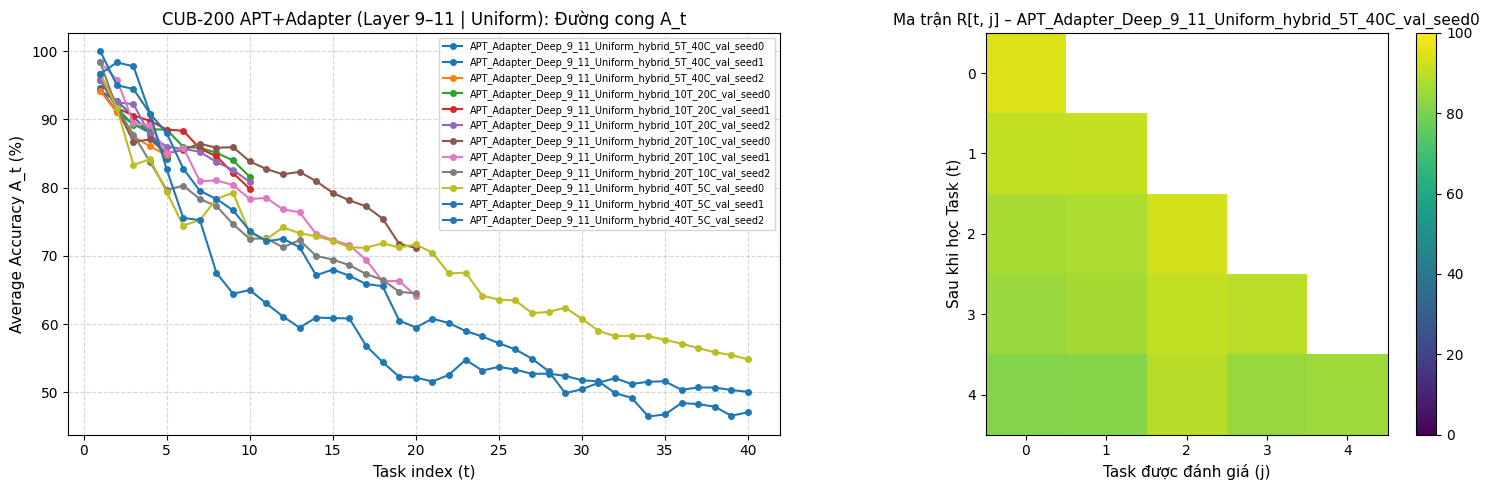

In [8]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Bảng tóm tắt kết quả chi tiết
rows = []
for k, r in RESULTS.items():
    clf = r.get("clf_type", "unknown")
    phase_m = r.get("phase", "val")
    ppf_m = r.get("ppf_mode", CFG.get("ppf_mode", "uniform"))
    method_name = f"APT + Adapter (Layer 9–11 | Uniform)"
    n_tasks = len(r.get("A_t", []))
    rows.append({
        "Experiment": k,
        "Method": method_name,
        "PPF Mode": ppf_m,
        "Phase": phase_m.upper(),
        "Tasks": n_tasks,
        "Seed": r.get("seed", 0),
        "Last Acc (%)": round(r.get("last", 0.0), 2),
        "Avg Acc (%)": round(r.get("avg", 0.0), 2),
        "Forgetting (%)": round(r.get("forgetting", 0.0), 2)
    })

df = pd.DataFrame(rows)
if not df.empty:
    print("📋 BẢNG TỔNG HỢP CHI TIẾT TỪNG SEED & TỪNG PHASE:", flush=True)
    display(df)
    df.to_csv(os.path.join(CFG["out_dir"], "summary_detailed.csv"), index=False)
    
    # 2. Thống kê tổng hợp (Mean +- Std) phân tách rõ theo Phase (VAL vs TEST)
    summary_stats = df.groupby(["Method", "PPF Mode", "Phase", "Tasks"]).agg({
        "Last Acc (%)": ["mean", "std"],
        "Avg Acc (%)": ["mean", "std"],
        "Forgetting (%)": ["mean", "std"]
    }).round(2)
    print("\n📊 THỐNG KÊ TRUNG BÌNH QUA CÁC SEED (VAL vs TEST):", flush=True)
    display(summary_stats)
    summary_stats.to_csv(os.path.join(CFG["out_dir"], "summary_mean_std.csv"))

# 3. Vẽ đồ thị đường cong A_t và ma trận R[t, j]
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Subplot 1: Độ chính xác trung bình A_t qua từng Task
colors = plt.cm.tab10(np.linspace(0, 1, max(len(RESULTS), 10)))
for idx, (k, r) in enumerate(RESULTS.items()):
    a_t = r.get("A_t", [])
    if a_t:
        axes[0].plot(range(1, len(a_t) + 1), a_t, marker="o", markersize=4, label=k, color=colors[idx % 10])

axes[0].set_xlabel("Task index (t)", fontsize=11)
axes[0].set_ylabel("Average Accuracy A_t (%)", fontsize=11)
axes[0].set_title("CUB-200 APT+Adapter (Layer 9–11 | Uniform): Đường cong A_t", fontsize=12)
axes[0].grid(True, linestyle="--", alpha=0.5)
axes[0].legend(loc="best", fontsize=7)

# Subplot 2: Ma trận R[t, j] của kịch bản đầu tiên hoặc seed 0
target_key = next((k for k in RESULTS if "test" in k and "seed0" in k), None)
if target_key is None:
    target_key = next((k for k in RESULTS if "seed0" in k), list(RESULTS.keys())[0] if RESULTS else None)

if target_key and "R" in RESULTS[target_key]:
    target_r = RESULTS[target_key]
    R = np.array(target_r["R"])
    R_masked = np.where(np.tril(np.ones_like(R)) > 0, R, np.nan)
    im = axes[1].imshow(R_masked, vmin=0, vmax=100, cmap="viridis")
    axes[1].set_title(f"Ma trận R[t, j] – {target_key}", fontsize=11)
    axes[1].set_xlabel("Task được đánh giá (j)", fontsize=11)
    axes[1].set_ylabel("Sau khi học Task (t)", fontsize=11)
    plt.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.savefig(os.path.join(CFG["out_dir"], "evaluation_curves.png"), dpi=150)
plt.show()
